# Exploratory Data Analysis — Credit Card Transaction Fraud

Dataset: [Credit Card Transactions Fraud Detection Dataset](https://www.kaggle.com/datasets/kartik2112/fraud-detection) (Sparkov simulated data).

Files expected in `data/`: `fraudTrain.csv`, `fraudTest.csv` (gitignored — download from the link above).

This notebook covers:
1. Loading & basic structure
2. Missing values
3. Target class balance (`is_fraud`)
4. Transaction amount
5. Category
6. Time-based patterns
7. Cardholder–merchant distance
8. Demographics (age, gender)
9. Correlations
10. Summary of findings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
%matplotlib inline

## 1. Load data

In [3]:
train = pd.read_csv("data/fraudTrain.csv", index_col=0)
test = pd.read_csv("data/fraudTest.csv", index_col=0)

print("train shape:", train.shape)
print("test shape:", test.shape)
train.head()

train shape: (1296675, 22)
test shape: (555719, 22)


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  object 
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  object 
 3   category               1296675 non-null  object 
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  object 
 6   last                   1296675 non-null  object 
 7   gender                 1296675 non-null  object 
 8   street                 1296675 non-null  object 
 9   city                   1296675 non-null  object 
 10  state                  1296675 non-null  object 
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop               

## 2. Missing values

In [ ]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:" if len(missing) else "No missing values in train set.")
missing

No missing values in train set.


Series([], dtype: int64)

## 3. Target class balance (`is_fraud`)

Fraud detection datasets are typically highly imbalanced — check the split before modeling (stratified sampling, resampling, class weights, etc. will likely be needed).

is_fraud
0    1289169
1       7506
Name: count, dtype: int64
is_fraud
0    99.421
1     0.579
Name: proportion, dtype: float64


/var/folders/q1/nxd01cjx58ddwb5f9669htwm0000gn/T/ipykernel_75143/3837490848.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])


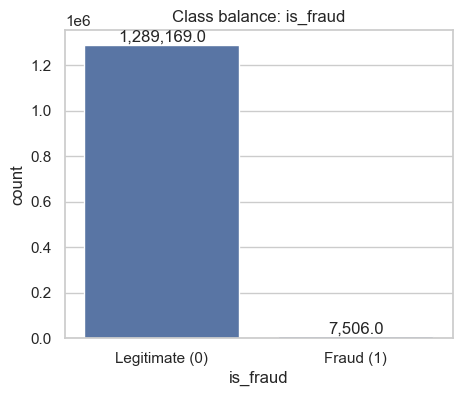

In [ ]:
fraud_counts = train["is_fraud"].value_counts()
fraud_pct = train["is_fraud"].value_counts(normalize=True) * 100

print(fraud_counts)
print(fraud_pct.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="is_fraud", data=train, ax=ax)
ax.set_title("Class balance: is_fraud")
ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])
for p in ax.patches:
    ax.annotate(f"{p.get_height():,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

## 4. Transaction amount (`amt`)

`amt` is heavily right-skewed: most transactions are small (well under $100) with a long tail of rare, large-value purchases stretching into the thousands. Plotted on a linear scale, that skew crams almost all of the data into a single spike near zero and hides the shape of the rest of the distribution. Log-scaling the x-axis (histogram) and y-axis (boxplot) spreads that out so the overall shape — and the gap between legitimate and fraudulent amounts — is actually visible. The tradeoff is that log scale visually compresses the largest outliers, so the boxplot's explicit outlier points and the `.describe()` table below are kept alongside it to not lose that signal.

In [ ]:
train["amt"].describe()

count    1.296675e+06
mean     7.035104e+01
std      1.603160e+02
min      1.000000e+00
25%      9.650000e+00
50%      4.752000e+01
75%      8.314000e+01
max      2.894890e+04
Name: amt, dtype: float64

/var/folders/q1/nxd01cjx58ddwb5f9669htwm0000gn/T/ipykernel_75143/3863952100.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Legitimate", "Fraud"])


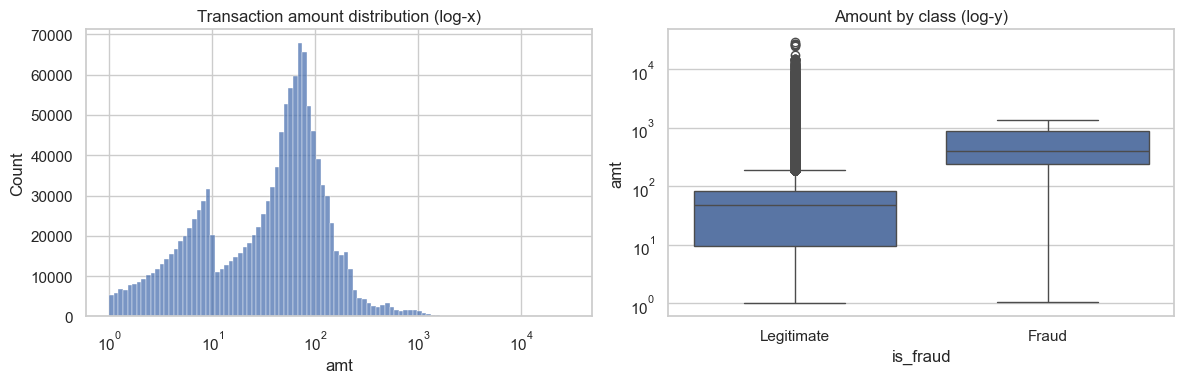

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# amt is right-skewed, so log-scale the amount axis to make the distribution
# readable instead of one spike near zero (see markdown cell above)
sns.histplot(train["amt"], bins=100, log_scale=(True, False), ax=axes[0])
axes[0].set_title("Transaction amount distribution (log-x)")

sns.boxplot(x="is_fraud", y="amt", data=train, ax=axes[1])
axes[1].set_yscale("log")  # same reason: spread out the skewed amounts
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_title("Amount by class (log-y)")

plt.tight_layout()
plt.show()

train.groupby("is_fraud")["amt"].describe()

## 5. Category

Some categories carry a `_pos` or `_net` suffix (`grocery_net`/`grocery_pos`, `misc_net`/`misc_pos`, `shopping_net`/`shopping_pos`) indicating **how** the purchase was made:
- `_pos` — point-of-sale, a physical/in-person transaction (card swiped/tapped at a store terminal)
- `_net` — online/e-commerce, a card-not-present transaction

Other categories (`entertainment`, `travel`, `gas_transport`, etc.) aren't split this way in this dataset. Card-not-present (`_net`) transactions are a classic higher-fraud-risk channel, so it's worth comparing fraud rates within a category (e.g. `grocery_net` vs. `grocery_pos`) rather than only across categories.

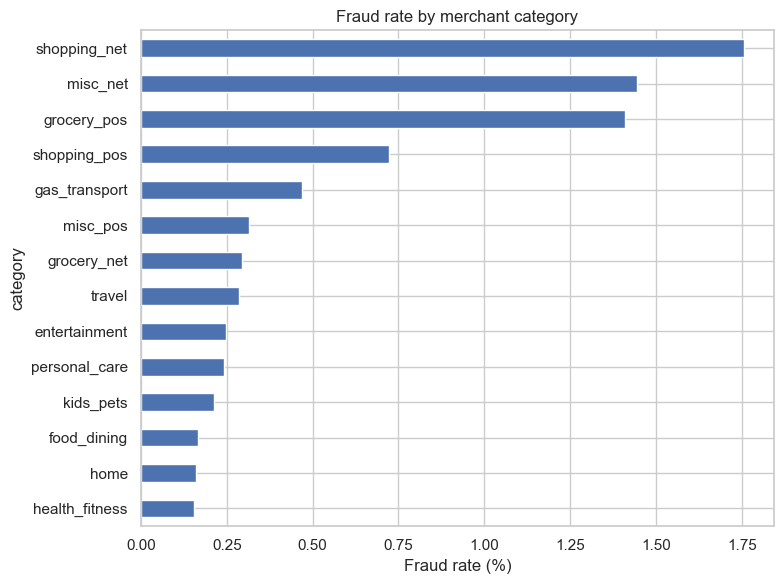

category
shopping_net      1.756149
misc_net          1.445795
grocery_pos       1.409761
shopping_pos      0.722538
gas_transport     0.469394
misc_pos          0.313853
grocery_net       0.294817
travel            0.286370
entertainment     0.247835
personal_care     0.242403
kids_pets         0.211439
food_dining       0.165098
home              0.160825
health_fitness    0.154869
Name: is_fraud, dtype: float64

In [ ]:
cat_fraud_rate = (
    train.groupby("category")["is_fraud"]
    .mean()
    .sort_values(ascending=False) * 100
)

fig, ax = plt.subplots(figsize=(8, 6))
cat_fraud_rate.plot(kind="barh", ax=ax)
ax.set_xlabel("Fraud rate (%)")
ax.set_title("Fraud rate by merchant category")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

cat_fraud_rate

## 6. Time-based patterns

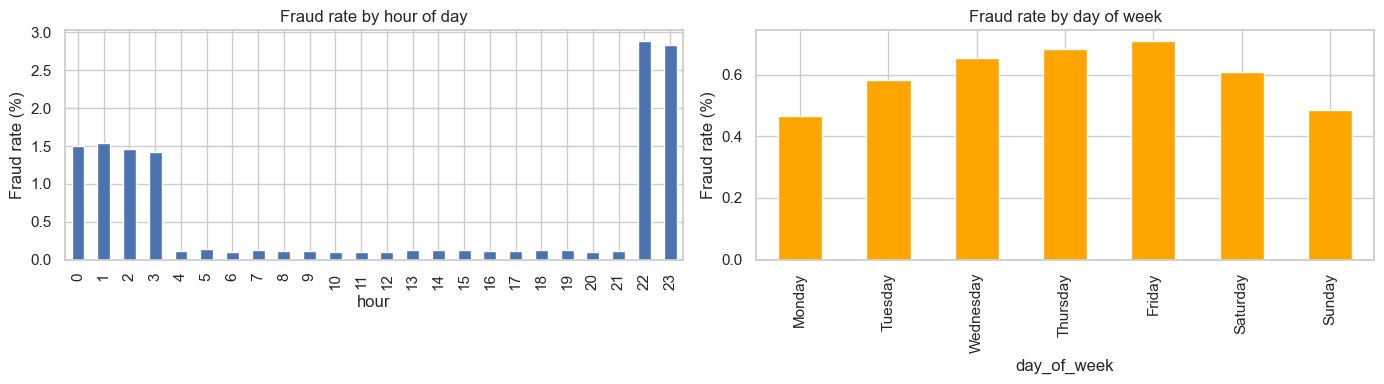

In [ ]:
train["trans_date_trans_time"] = pd.to_datetime(train["trans_date_trans_time"])
train["hour"] = train["trans_date_trans_time"].dt.hour
train["day_of_week"] = train["trans_date_trans_time"].dt.day_name()
train["month"] = train["trans_date_trans_time"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

hourly_rate = train.groupby("hour")["is_fraud"].mean() * 100
hourly_rate.plot(kind="bar", ax=axes[0])
axes[0].set_title("Fraud rate by hour of day")
axes[0].set_ylabel("Fraud rate (%)")

dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_rate = train.groupby("day_of_week")["is_fraud"].mean().reindex(dow_order) * 100
dow_rate.plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Fraud rate by day of week")
axes[1].set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.show()

## 7. Cardholder–merchant distance

Compute the great-circle distance between the cardholder's location (`lat`, `long`) and the merchant's location (`merch_lat`, `merch_long`) — fraud often correlates with larger distances.

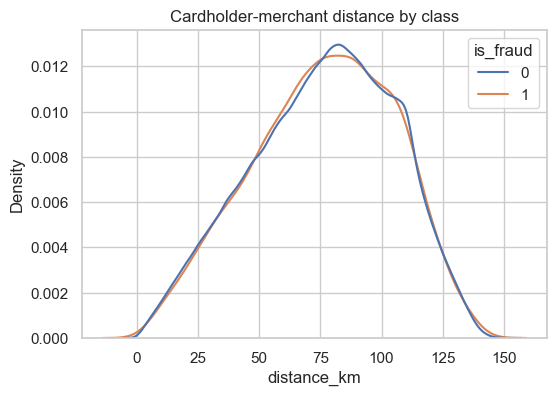

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,76.113756,29.119051,0.022255,55.332701,78.233012,98.504498,152.117173
1,7506.0,76.268330,28.752602,0.738769,55.632890,77.931954,98.391090,144.522410


In [ ]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

train["distance_km"] = haversine_km(train["lat"], train["long"], train["merch_lat"], train["merch_long"])

fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=train, x="distance_km", hue="is_fraud", common_norm=False, ax=ax)
ax.set_title("Cardholder-merchant distance by class")
plt.show()

train.groupby("is_fraud")["distance_km"].describe()

## 8. Demographics

The raw dataset doesn't include age directly, only `dob` (date of birth), so age is derived here as the cardholder's age *at the time of the transaction* (`trans_date_trans_time - dob`), not their age today — this matters since transactions span multiple years and a fixed "current age" would be wrong for older transactions.

We look at age and gender because fraud isn't always evenly distributed across a customer base — some demographic segments can be targeted more (e.g. via stolen-card patterns) or be more susceptible to scams than others. The boxplot compares the age distribution of legitimate vs. fraudulent transactions to check for a shift; the bar chart compares fraud rate (not raw count) by gender so the comparison isn't skewed by one gender simply having more transactions overall.

/var/folders/q1/nxd01cjx58ddwb5f9669htwm0000gn/T/ipykernel_75143/2345712560.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Legitimate", "Fraud"])


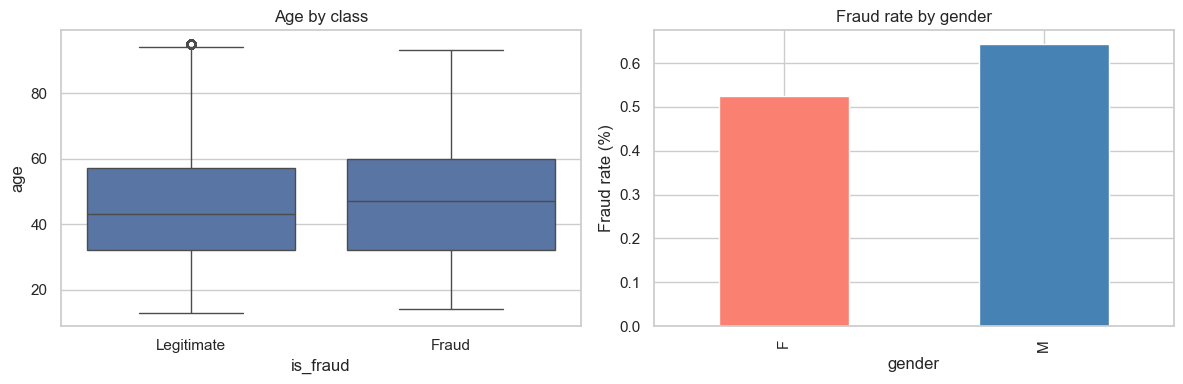

In [ ]:
train["dob"] = pd.to_datetime(train["dob"])
train["age"] = ((train["trans_date_trans_time"] - train["dob"]).dt.days / 365.25).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x="is_fraud", y="age", data=train, ax=axes[0])
axes[0].set_xticklabels(["Legitimate", "Fraud"])
axes[0].set_title("Age by class")

gender_rate = train.groupby("gender")["is_fraud"].mean() * 100
gender_rate.plot(kind="bar", ax=axes[1], color=["salmon", "steelblue"])
axes[1].set_title("Fraud rate by gender")
axes[1].set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.show()

## 9. Correlations (numeric features)

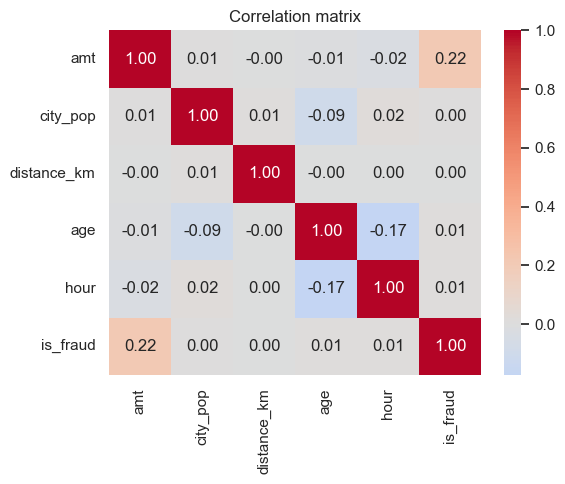

In [ ]:
numeric_cols = ["amt", "city_pop", "distance_km", "age", "hour", "is_fraud"]
corr = train[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

## 10. Summary of findings

- **Class imbalance**: fraud is a small fraction of transactions — plan for resampling/class weighting/appropriate metrics (precision-recall, F1, ROC-AUC) rather than accuracy.
- **Amount**: fraudulent transactions tend to skew toward higher amounts than legitimate ones.
- **Category**: fraud rate varies notably by merchant category — some categories are disproportionately targeted.
- **Time**: fraud is not uniform across hours/days — certain hours show elevated fraud rates.
- **Distance**: fraudulent transactions tend to occur further from the cardholder's home location.
- **Demographics**: age and gender show some association with fraud rate, though weaker than amount/category/distance.

_Next steps: feature engineering (distance, age, time features already derived above), encoding categorical variables, train/test split evaluation using the provided `fraudTrain.csv`/`fraudTest.csv` split, and baseline model comparison._